In [96]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

In [97]:
import pandas as pd
import numpy as np

In [98]:
df = pd.read_csv('seeds_dataset.txt', sep='\s+', header=None)
df.columns = ['feature-1', 'feature-2', 'feature-3', 'feature-4', 'feature-5', 'feature-6', 'feature-7', 'class']
df

,feature-1,feature-2,feature-3,feature-4,feature-5,feature-6,feature-7,class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1
...,...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3


## Уникальные значения в столбце

In [100]:
print(df['feature-1'].nunique())
print(df['feature-2'].nunique())
print(df['feature-3'].nunique())
print(df['feature-4'].nunique())
print(df['feature-5'].nunique())
print(df['feature-6'].nunique())
print(df['feature-7'].nunique())

193
170
186
188
184
207
148


## Нормализация 

In [102]:
from sklearn.preprocessing import MinMaxScaler

x = df.drop('class', axis = 1)
scaler = MinMaxScaler()
data_arr = scaler.fit_transform(x)
data = pd.DataFrame(data_arr, columns=x.columns)
data['class'] = df['class']
data

,feature-1,feature-2,feature-3,feature-4,feature-5,feature-6,feature-7,class
0,0.440982,0.502066,0.570780,0.486486,0.486101,0.189302,0.345150,1
1,0.405099,0.446281,0.662432,0.368806,0.501069,0.032883,0.215165,1
2,0.349386,0.347107,0.879310,0.220721,0.503920,0.251453,0.150665,1
3,0.306893,0.316116,0.793103,0.239302,0.533856,0.194243,0.140817,1
4,0.524079,0.533058,0.864791,0.427365,0.664291,0.076701,0.322994,1
...,...,...,...,...,...,...,...,...
205,0.151086,0.163223,0.637024,0.134009,0.250178,0.372635,0.172821,3
206,0.060434,0.097107,0.390200,0.135698,0.117605,0.462872,0.238306,3
207,0.246459,0.258264,0.727768,0.189752,0.429081,0.981667,0.264402,3
208,0.118036,0.165289,0.399274,0.155405,0.146828,0.368344,0.258493,3


In [103]:
data.min(), data.max()

(feature-1    0.0
 feature-2    0.0
 feature-3    0.0
 feature-4    0.0
 feature-5    0.0
 feature-6    0.0
 feature-7    0.0
 class        1.0
 dtype: float64,
 feature-1    1.0
 feature-2    1.0
 feature-3    1.0
 feature-4    1.0
 feature-5    1.0
 feature-6    1.0
 feature-7    1.0
 class        3.0
 dtype: float64)

## Удаление столбца класса

In [105]:
from sklearn.model_selection import train_test_split

X = data.drop('class', axis = 1)
Y = data['class']
X.shape, Y.shape

((210, 7), (210,))

## KMeans

For n_clusters = 2, the average silhouette_score is : 0.5051
For n_clusters = 3, the average silhouette_score is : 0.4221
For n_clusters = 4, the average silhouette_score is : 0.3377
For n_clusters = 5, the average silhouette_score is : 0.2992
For n_clusters = 6, the average silhouette_score is : 0.3035
For n_clusters = 7, the average silhouette_score is : 0.2790
For n_clusters = 8, the average silhouette_score is : 0.2588


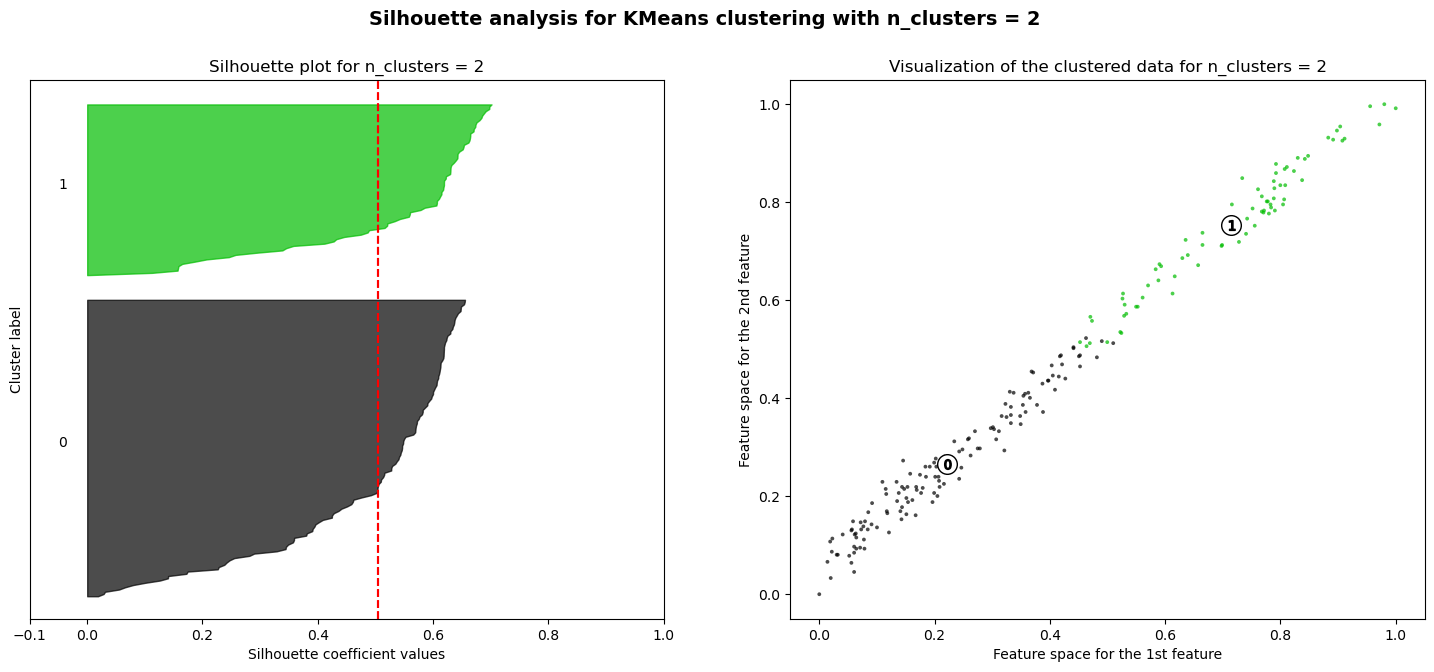

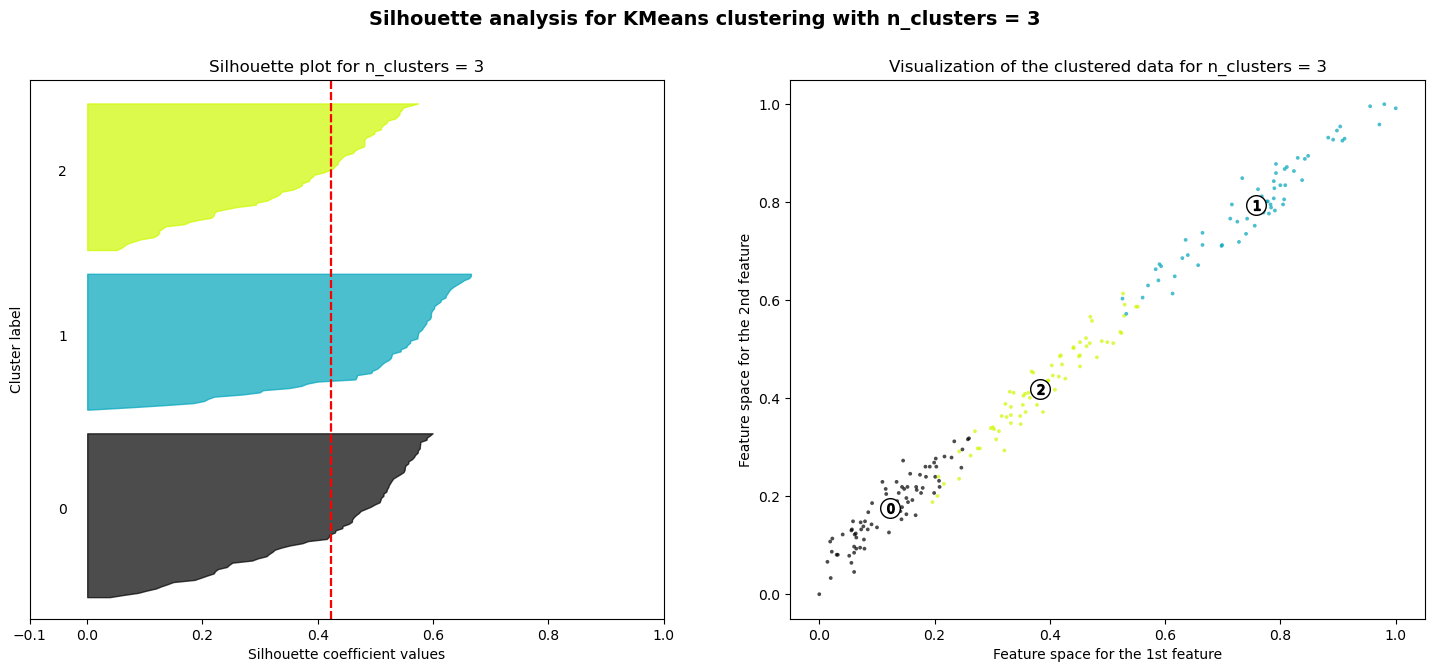

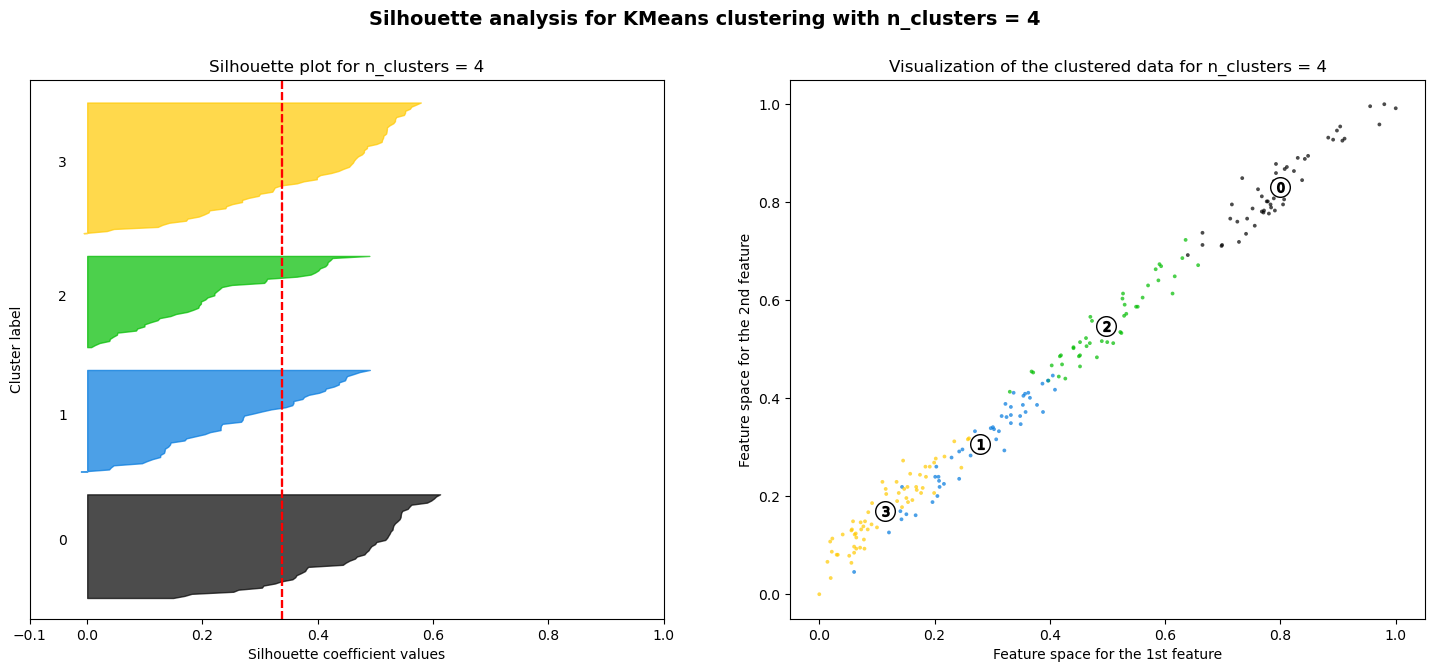

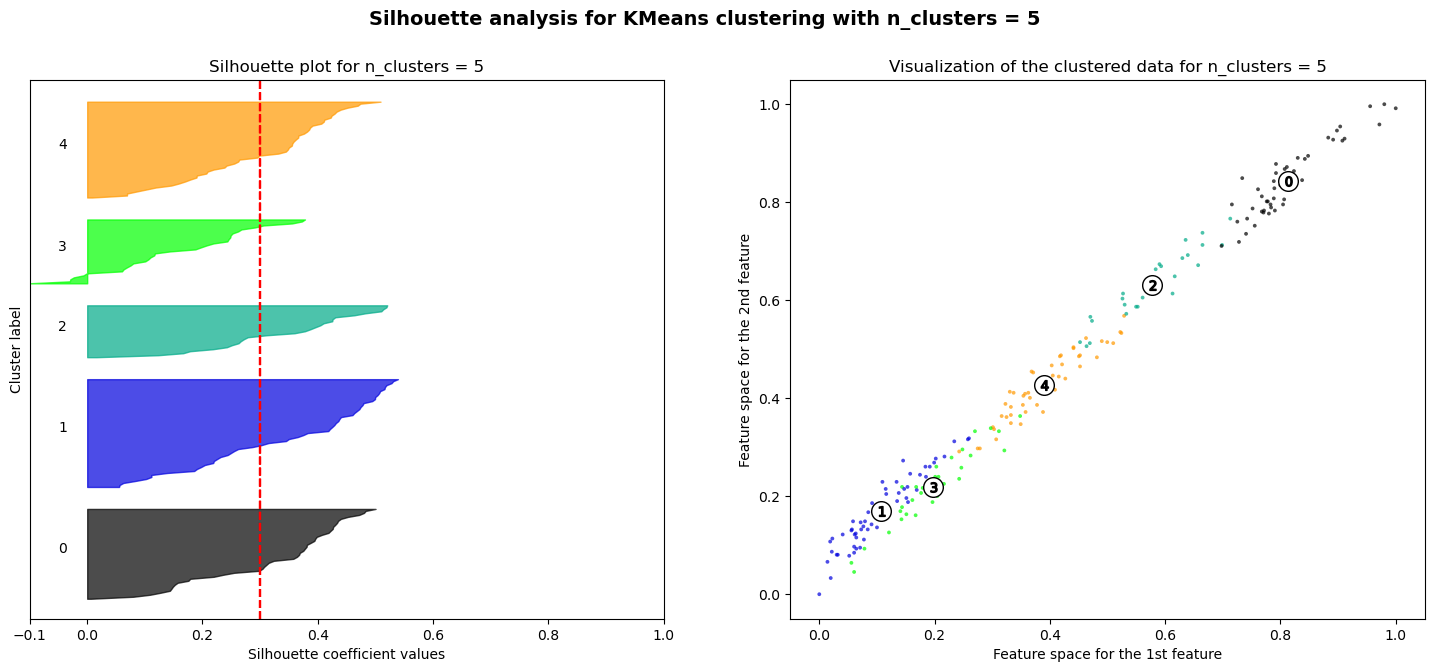

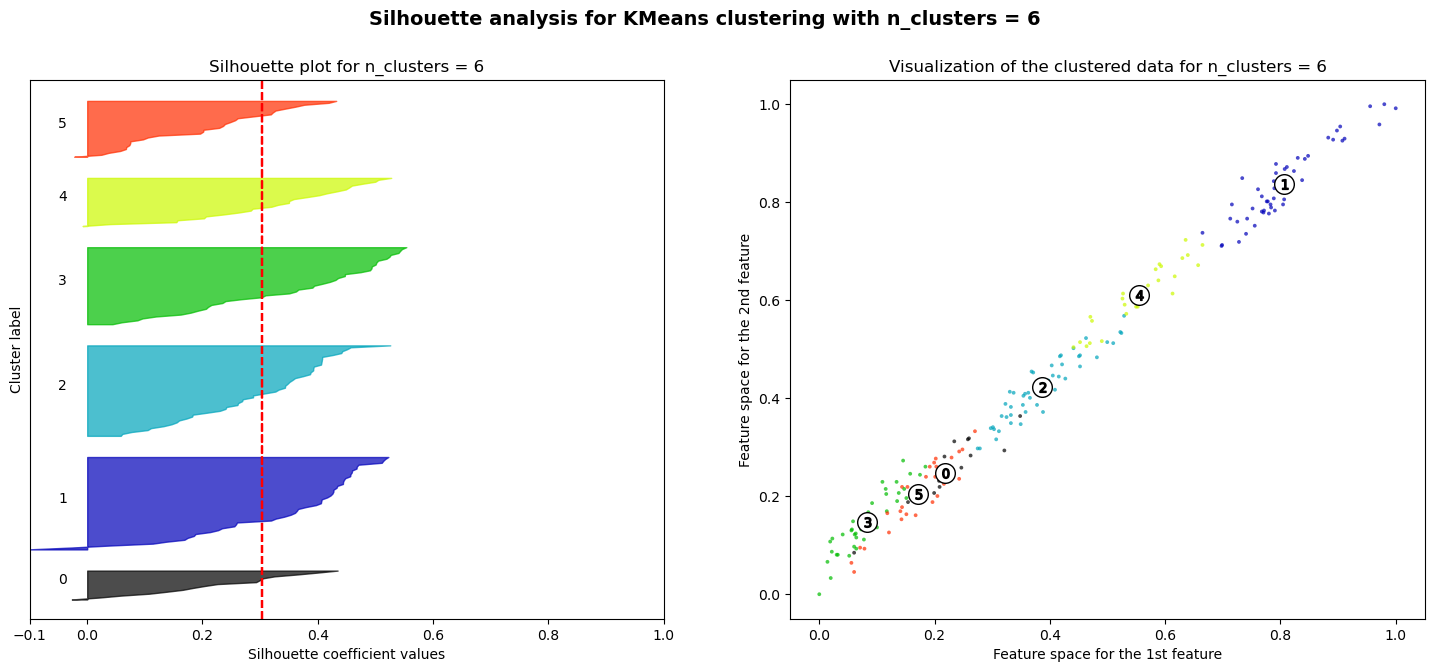

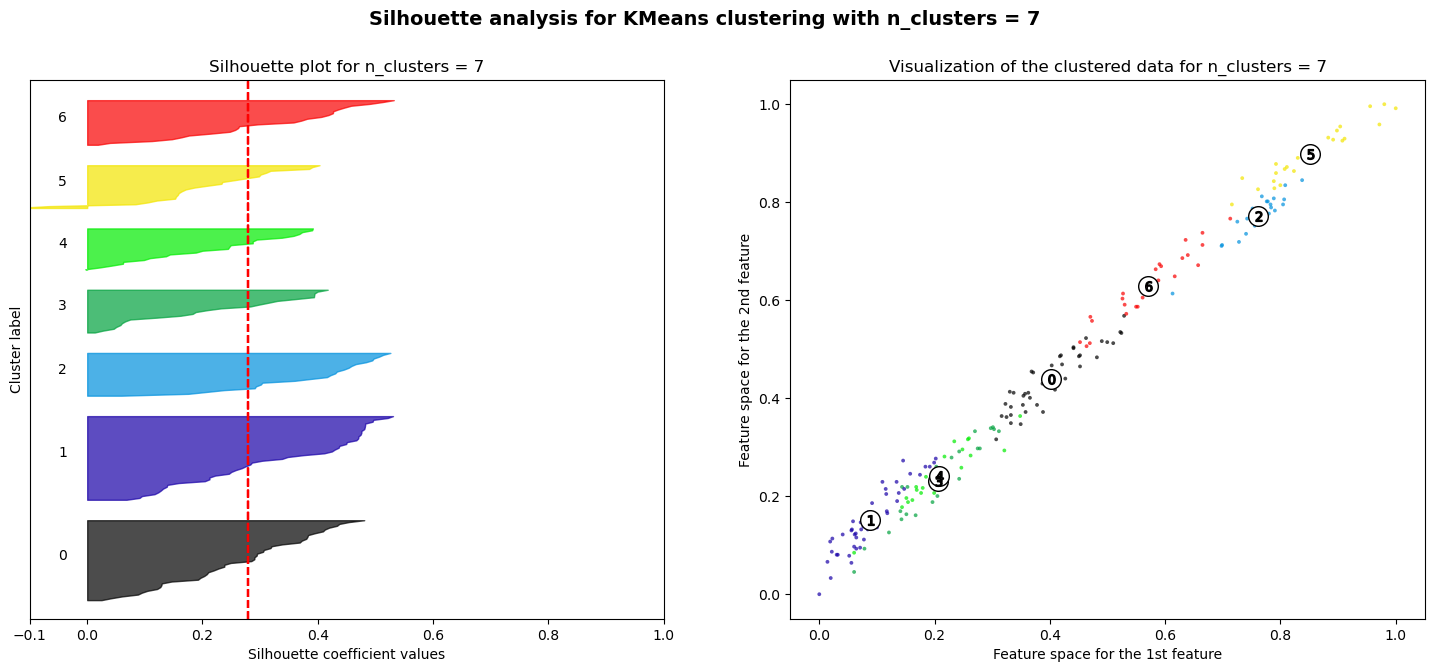

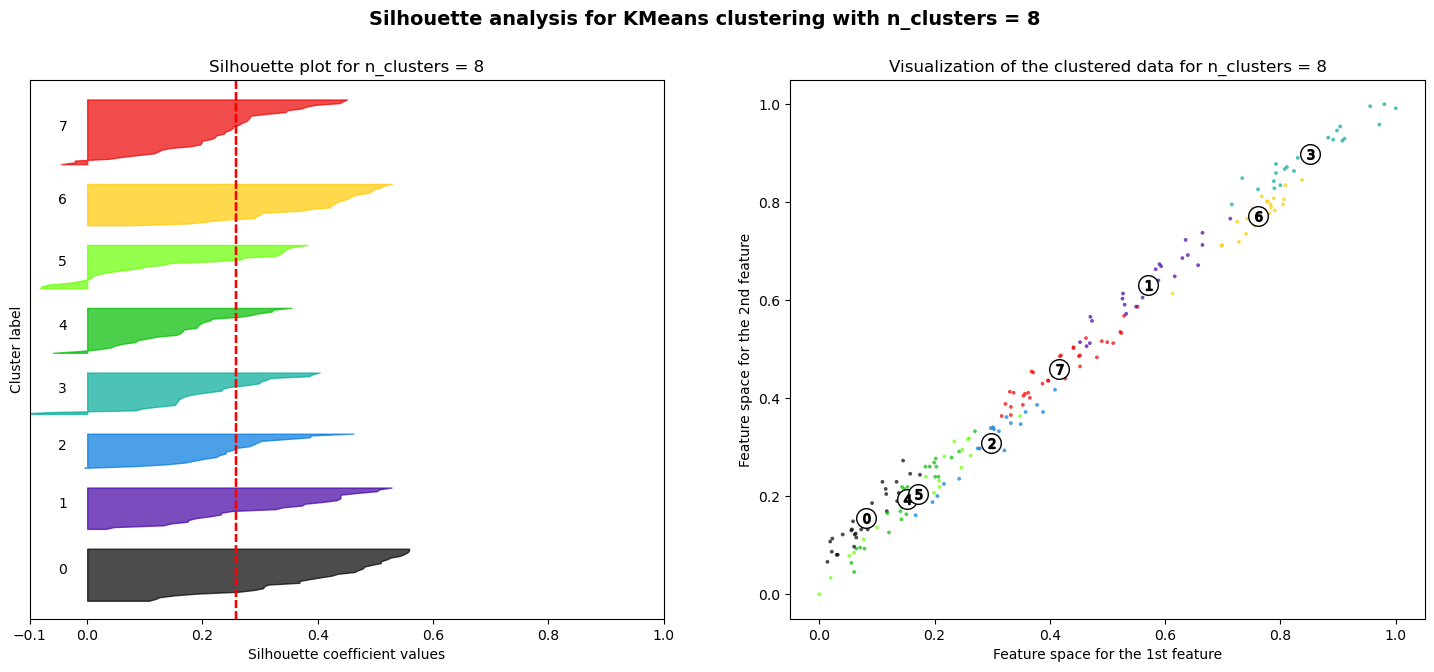

In [107]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.cm as cm
import matplotlib.pyplot as plt

X = np.array(X)
range_n_clusters = [2, 3, 4, 5, 6, 7, 8]

for n_clusters in range_n_clusters:

    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    ax1.set_xlim([-0.1, 1])
    ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

    clusterer = KMeans(n_clusters=n_clusters, random_state=10, n_init = 15)
    cluster_labels = clusterer.fit_predict(X)

    silhouette_avg = silhouette_score(X, cluster_labels)
    sample_silhouette_values = silhouette_samples(X, cluster_labels)
    print(f"For n_clusters = {n_clusters}, the average silhouette_score is : {silhouette_avg:.4f}")

    # Первый подграфик
    y_lower = 10
    for i in range(n_clusters):
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values, facecolor=color, edgecolor=color, alpha=0.7)

        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
        y_lower = y_upper + 10

        ax1.set_title(f"Silhouette plot for n_clusters = {n_clusters}")
        ax1.set_xlabel("Silhouette coefficient values")
        ax1.set_ylabel("Cluster label")
        ax1.axvline(x=silhouette_avg, color="red", linestyle="--")
        ax1.set_yticks([])
        ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

        # Второй подграфик: визуализация кластеров
    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(X[:, 0], X[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k")

    centers = clusterer.cluster_centers_
    ax2.scatter(centers[:, 0], centers[:, 1], marker="o", c="white", alpha=1, s=200, edgecolor="k")

    for i, c in enumerate(centers):
        ax2.scatter(c[0], c[1], marker=f"${i}$", alpha=1, s=50, edgecolor="k")

    ax2.set_title(f"Visualization of the clustered data for n_clusters = {n_clusters}")
    ax2.set_xlabel("Feature space for the 1st feature")
    ax2.set_ylabel("Feature space for the 2nd feature")

    plt.suptitle(f"Silhouette analysis for KMeans clustering with n_clusters = {n_clusters}", fontsize=14, fontweight="bold")

plt.show()

## Алгоритм Agglomerative Clustering

For n_clusters = 2, the average silhouette_score is: 0.4935
For n_clusters = 3, the average silhouette_score is: 0.3810
For n_clusters = 4, the average silhouette_score is: 0.3320
For n_clusters = 5, the average silhouette_score is: 0.2744
For n_clusters = 6, the average silhouette_score is: 0.2728
For n_clusters = 7, the average silhouette_score is: 0.2711
For n_clusters = 8, the average silhouette_score is: 0.2334


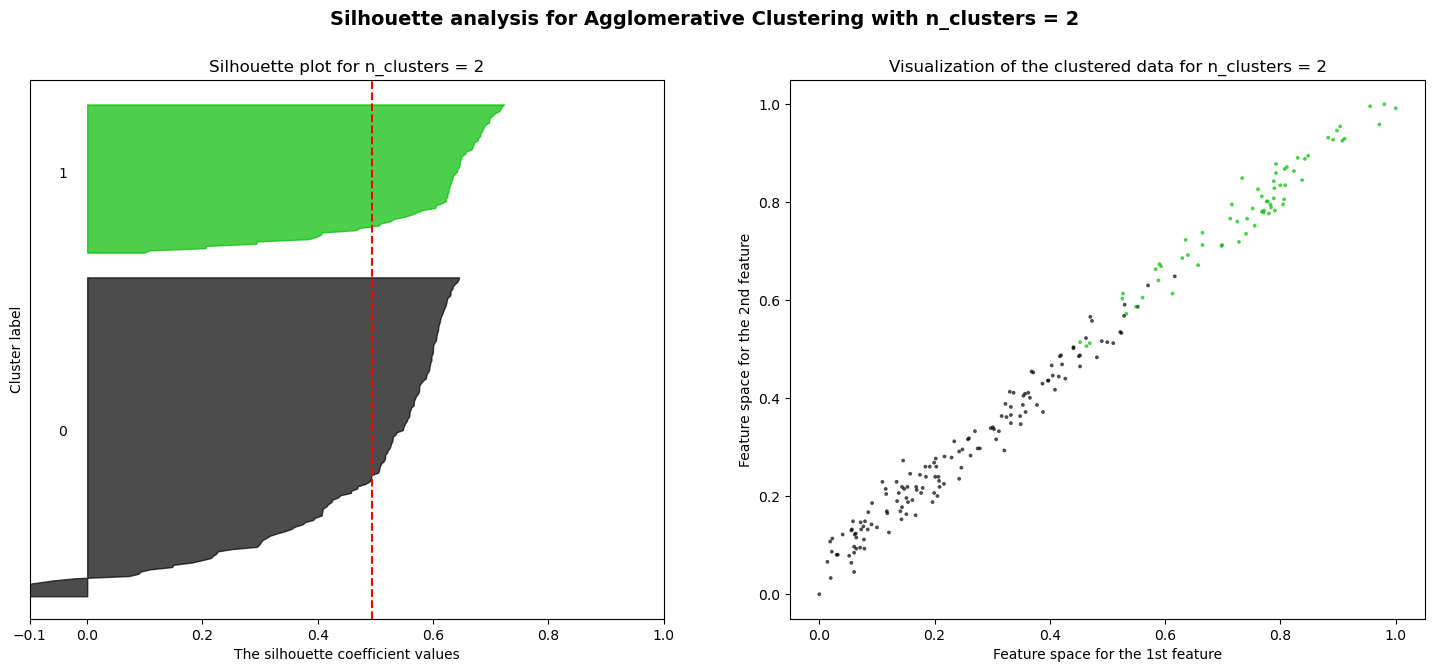

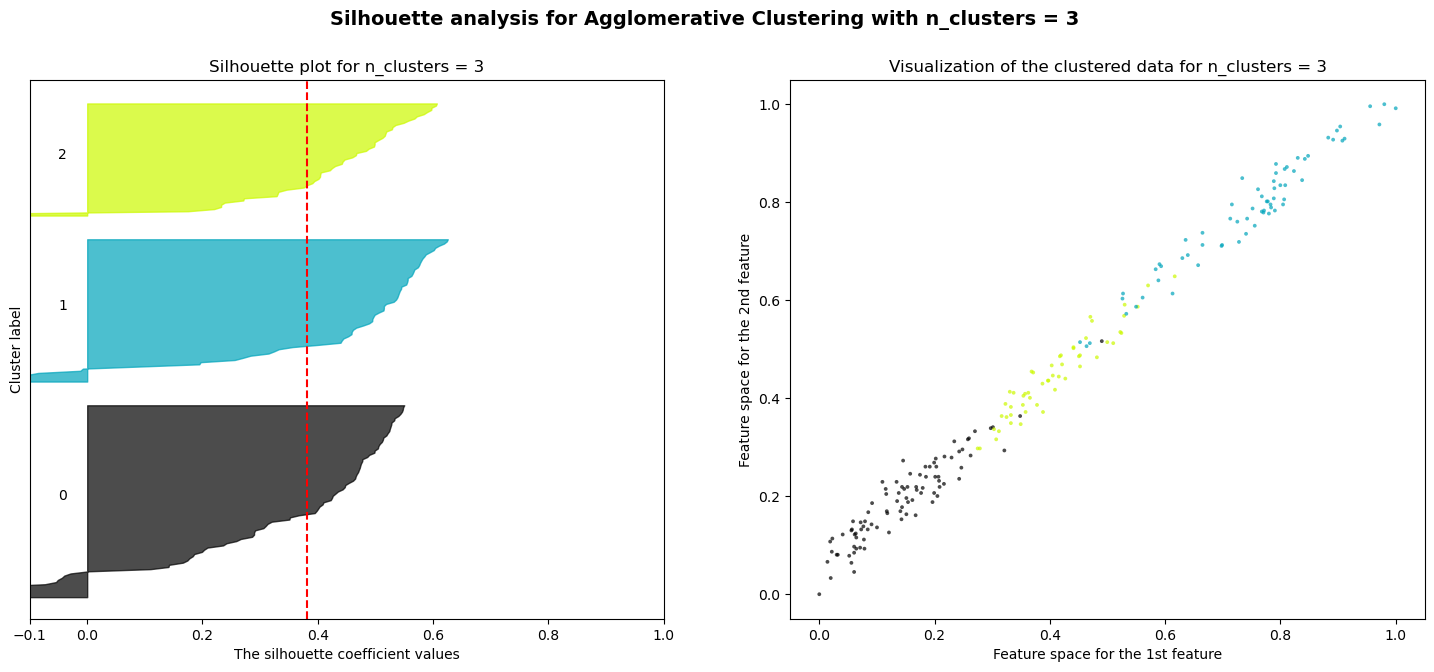

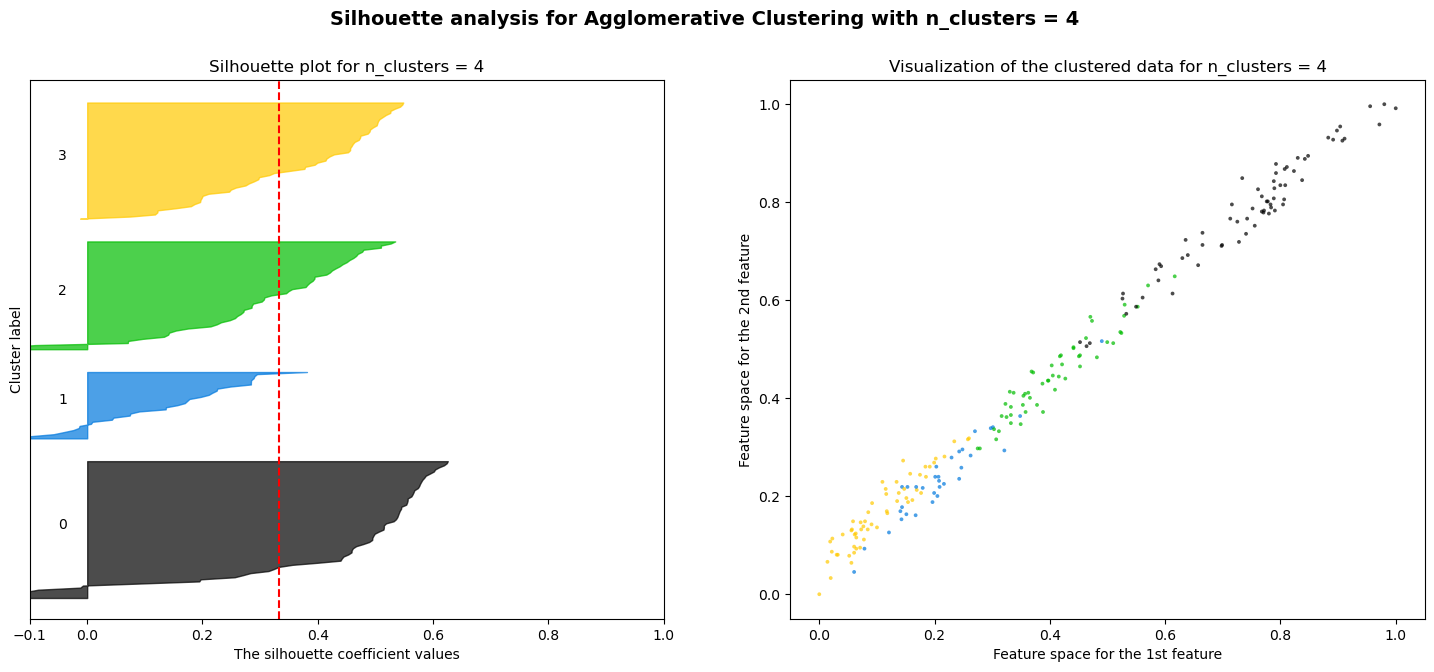

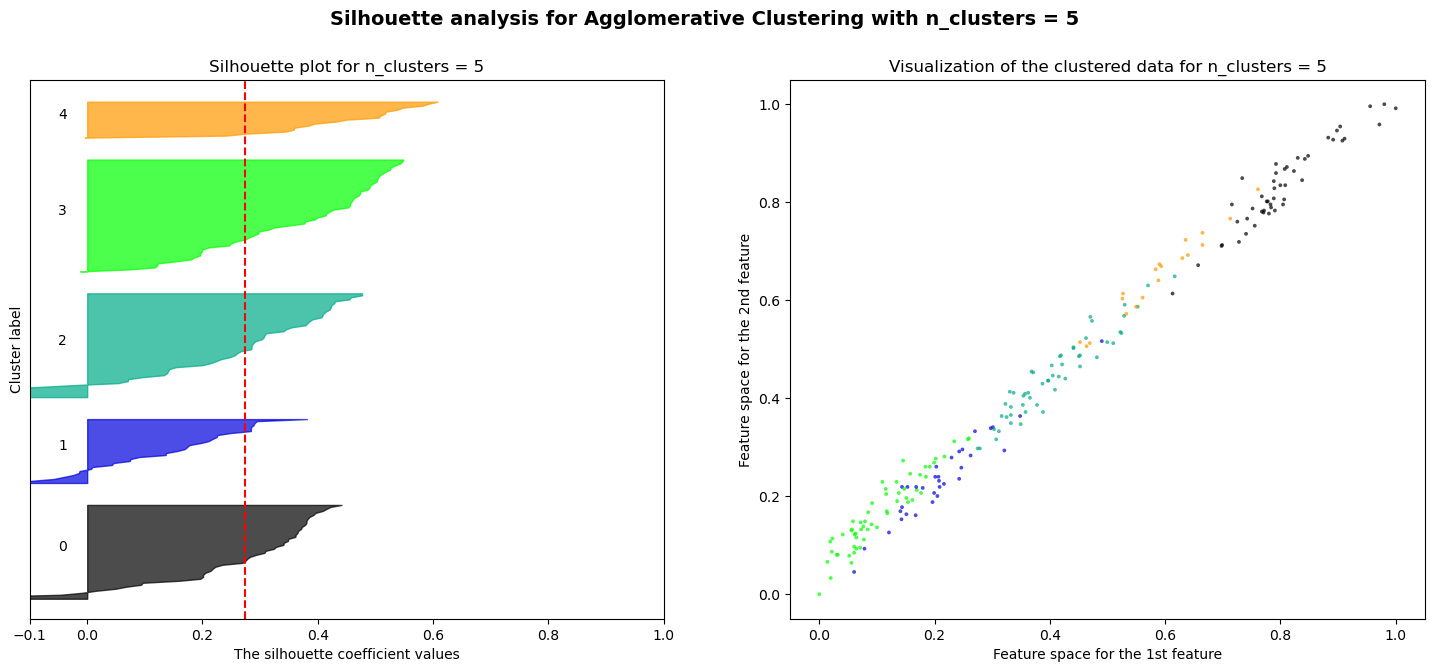

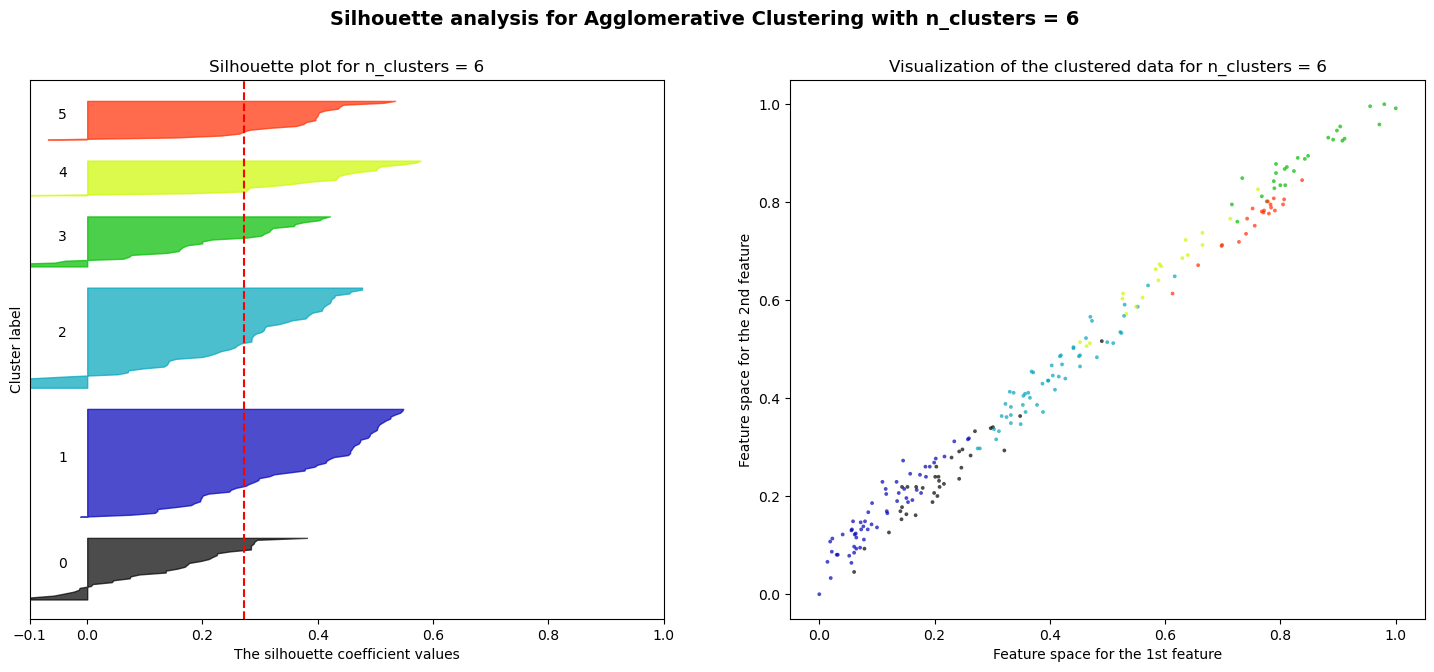

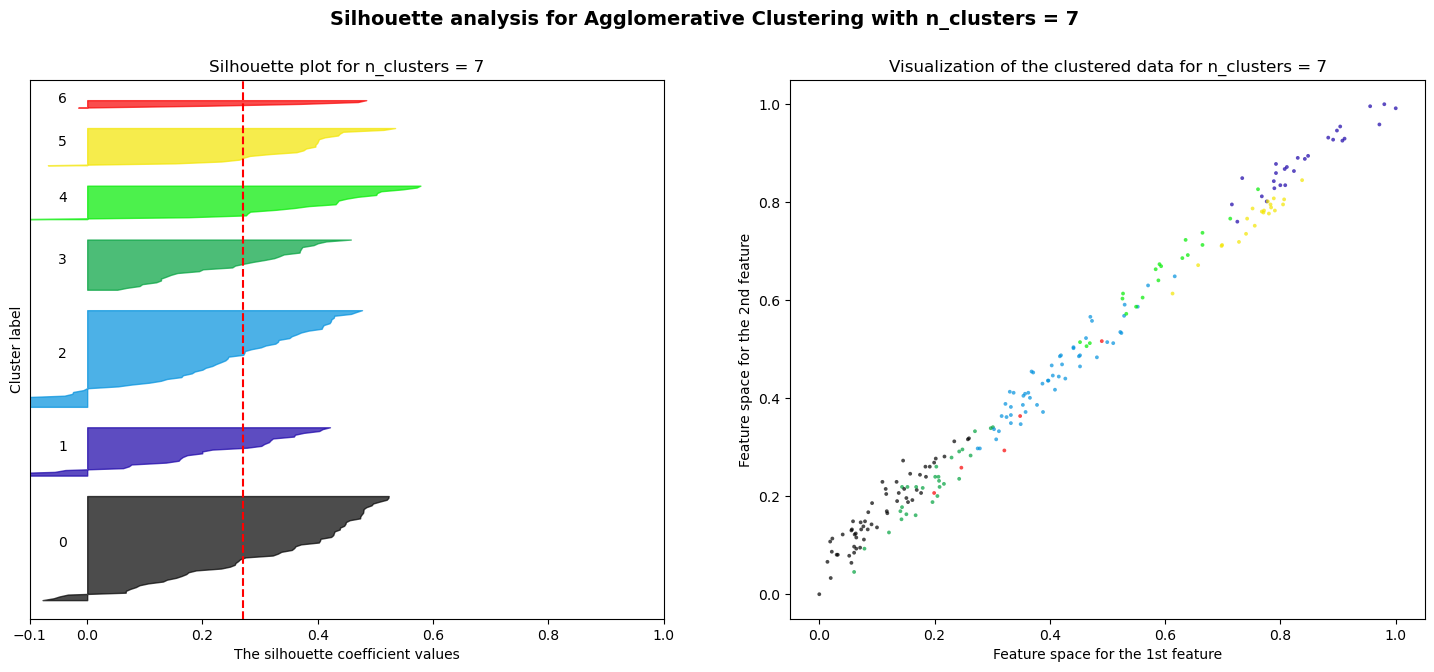

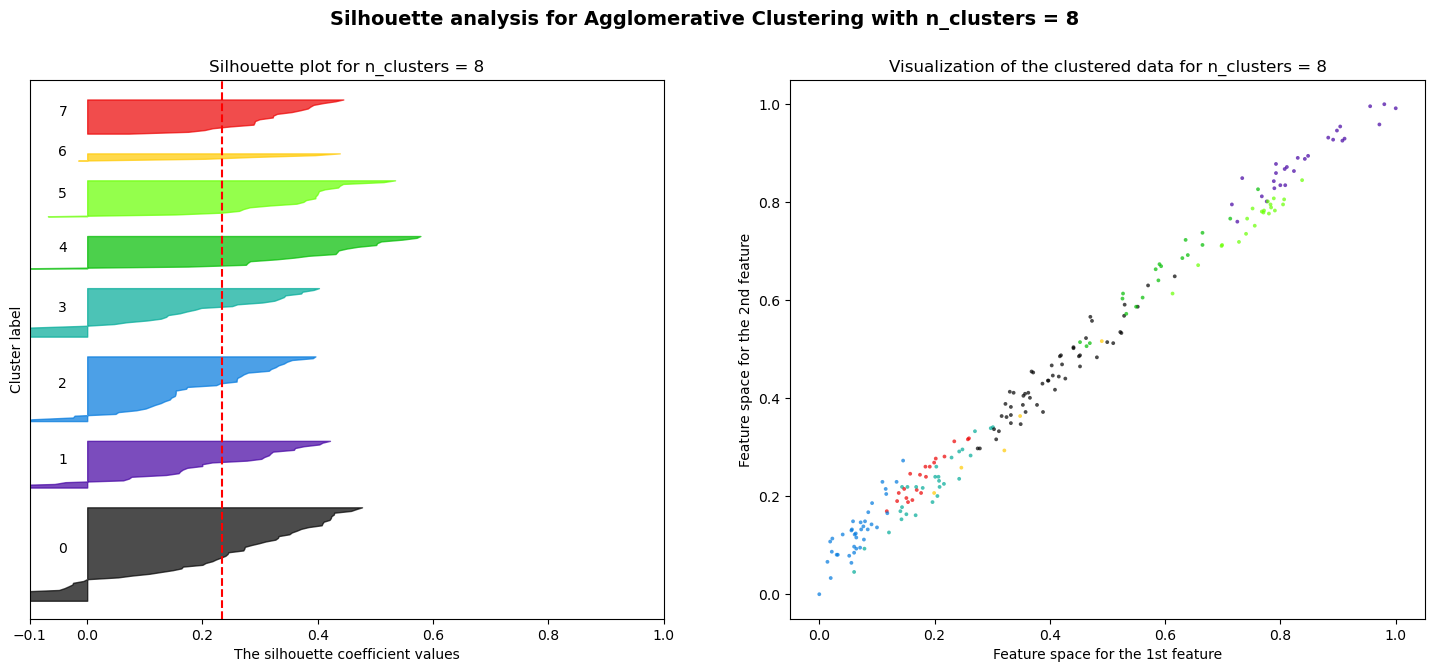

In [109]:
for n_clusters in range_n_clusters:
    # Создаём подграфики с 1 строкой и 2 колонками
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # Первый подграфик: график силуэтного коэффициента
    ax1.set_xlim([-0.1, 1])
    ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

    # Инициализируем Agglomerative Clustering
    clusterer = AgglomerativeClustering(n_clusters=n_clusters)
    cluster_labels = clusterer.fit_predict(X)

    # Средний силуэтный коэффициент
    silhouette_avg = silhouette_score(X, cluster_labels)
    print(f"For n_clusters = {n_clusters}, the average silhouette_score is: {silhouette_avg:.4f}")

    # Считаем силуэтные коэффициенты для каждого образца
    sample_silhouette_values = silhouette_samples(X, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Силуэтные коэффициенты для кластера i
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Подписываем номера кластеров
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        y_lower = y_upper + 10

    ax1.set_title(f"Silhouette plot for n_clusters = {n_clusters}")
    ax1.set_xlabel("The silhouette coefficient values")
    ax1.set_ylabel("Cluster label")

    # Вертикальная линия для среднего силуэтного коэффициента
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])  # Убираем метки на оси Y
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # Второй подграфик: визуализация кластеров
    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(X[:, 0], X[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k")

    ax2.set_title(f"Visualization of the clustered data for n_clusters = {n_clusters}")
    ax2.set_xlabel("Feature space for the 1st feature")
    ax2.set_ylabel("Feature space for the 2nd feature")

    plt.suptitle( f"Silhouette analysis for Agglomerative Clustering with n_clusters = {n_clusters}", fontsize=14, fontweight="bold")

plt.show()

## Алгоритм Gaussian Mixture Model

For n_clusters = 2, the average silhouette_score is: 0.4781
For n_clusters = 3, the average silhouette_score is: 0.3969
For n_clusters = 4, the average silhouette_score is: 0.3401
For n_clusters = 5, the average silhouette_score is: 0.2847
For n_clusters = 6, the average silhouette_score is: 0.2502
For n_clusters = 7, the average silhouette_score is: 0.2364
For n_clusters = 8, the average silhouette_score is: 0.2517


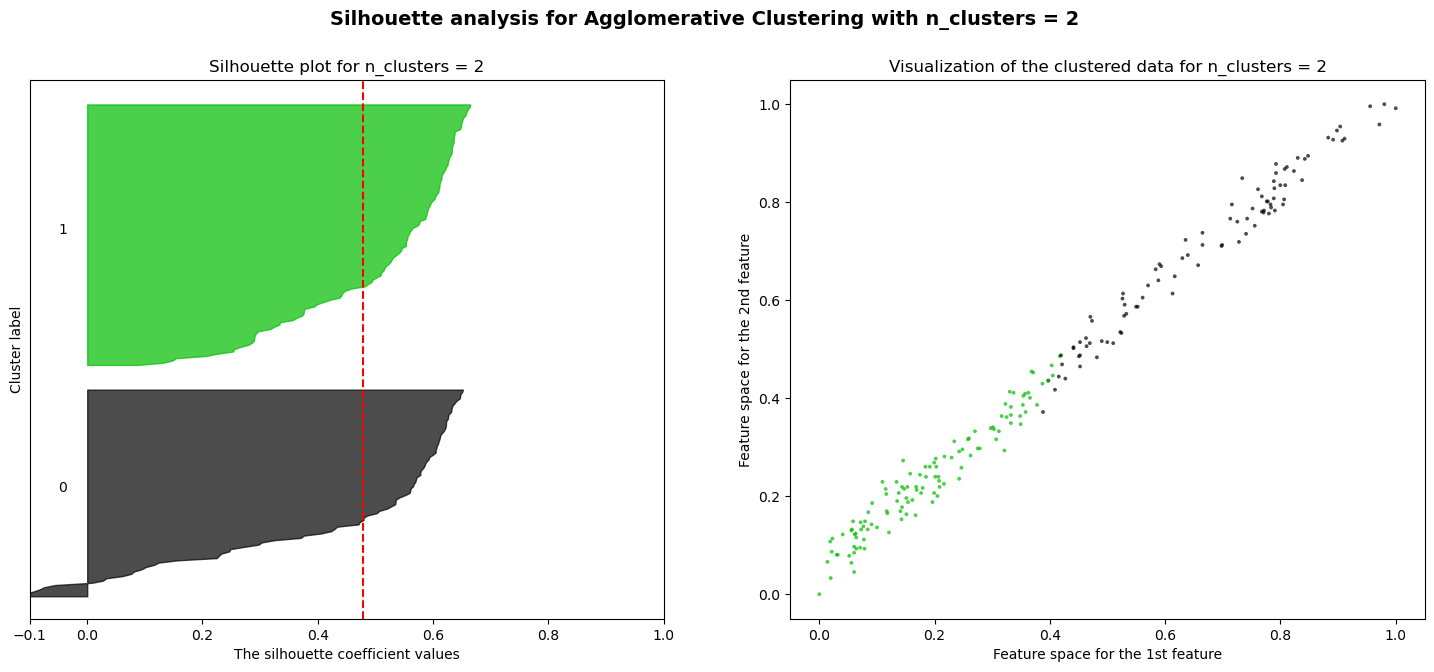

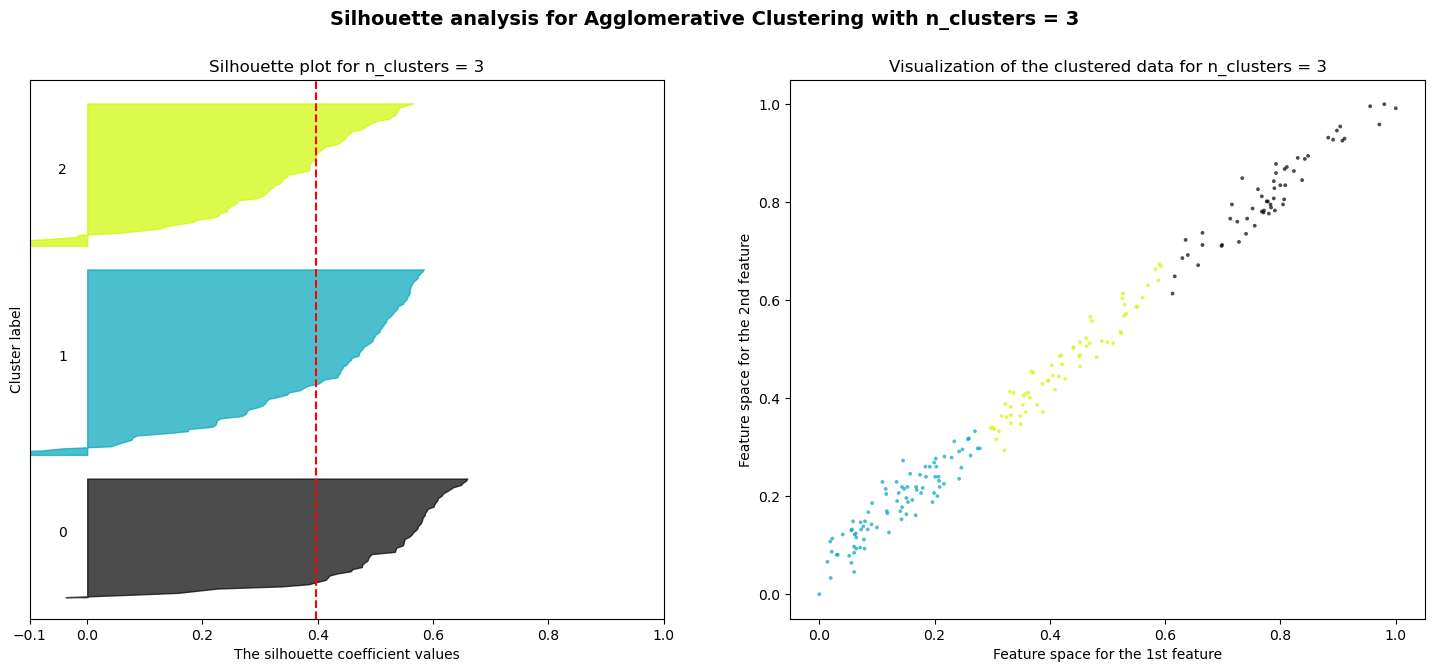

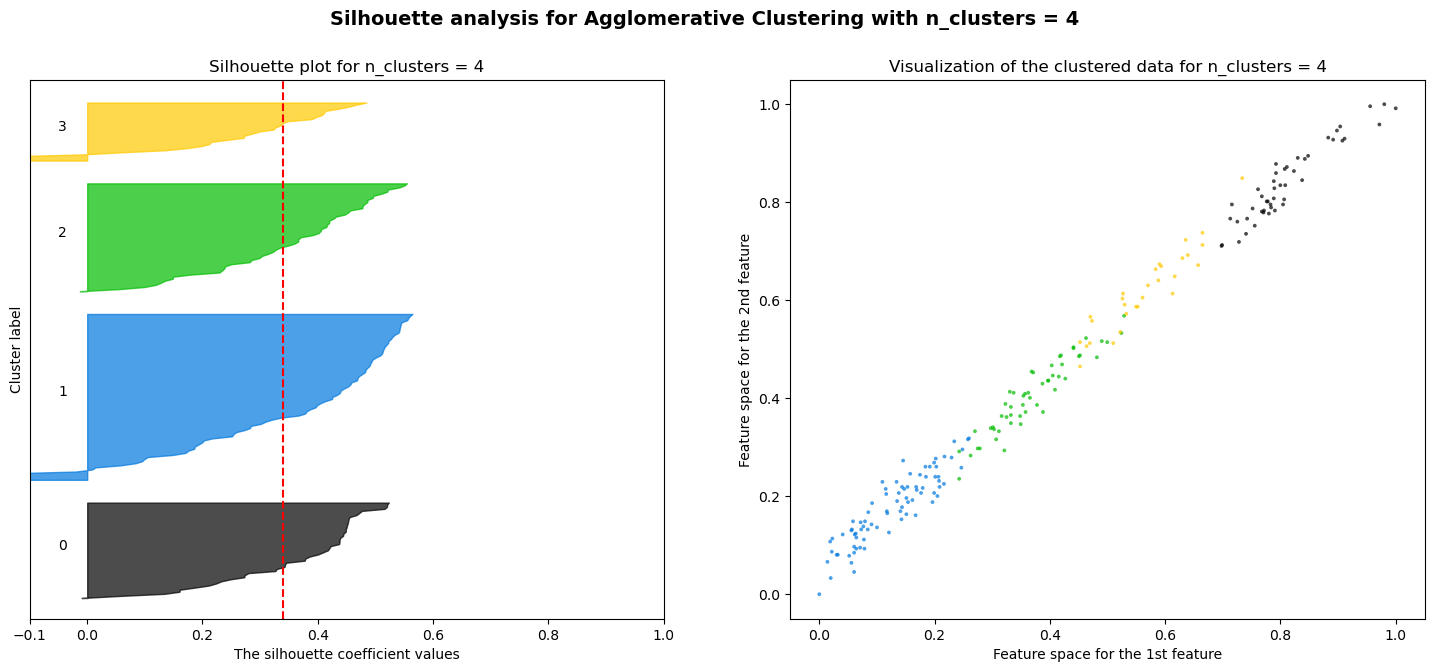

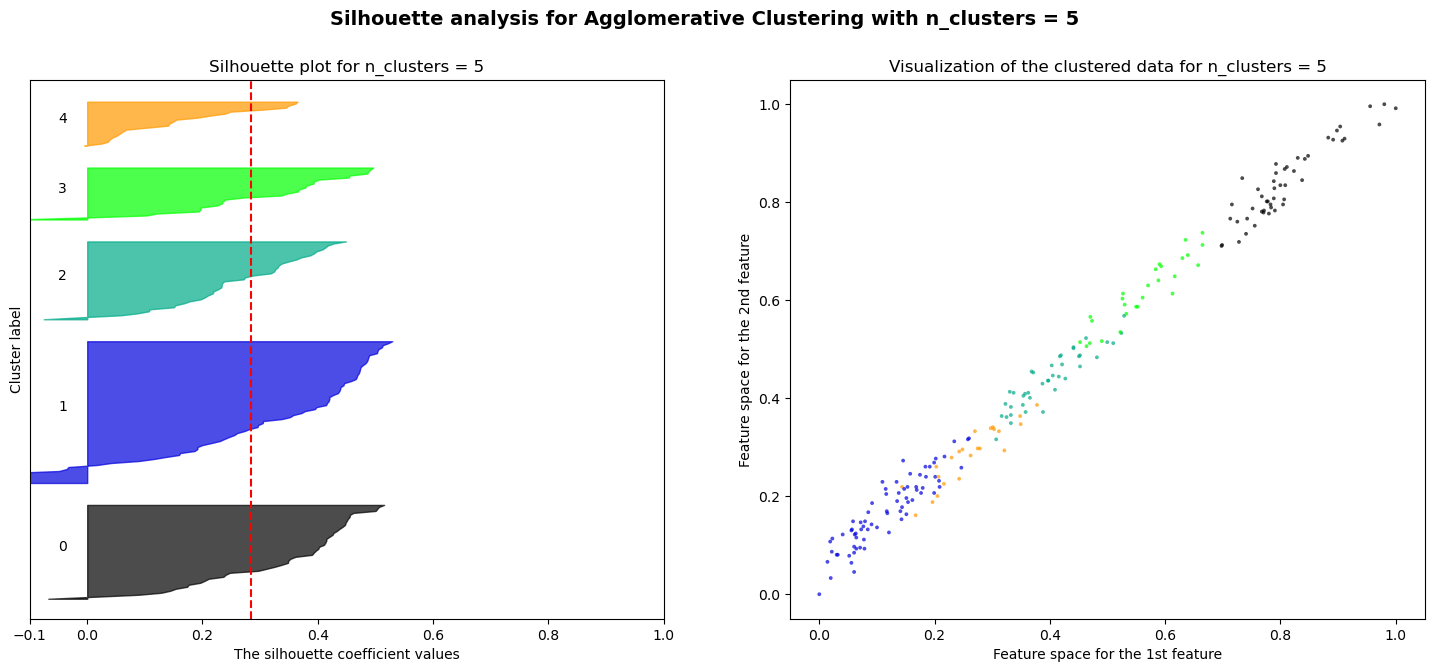

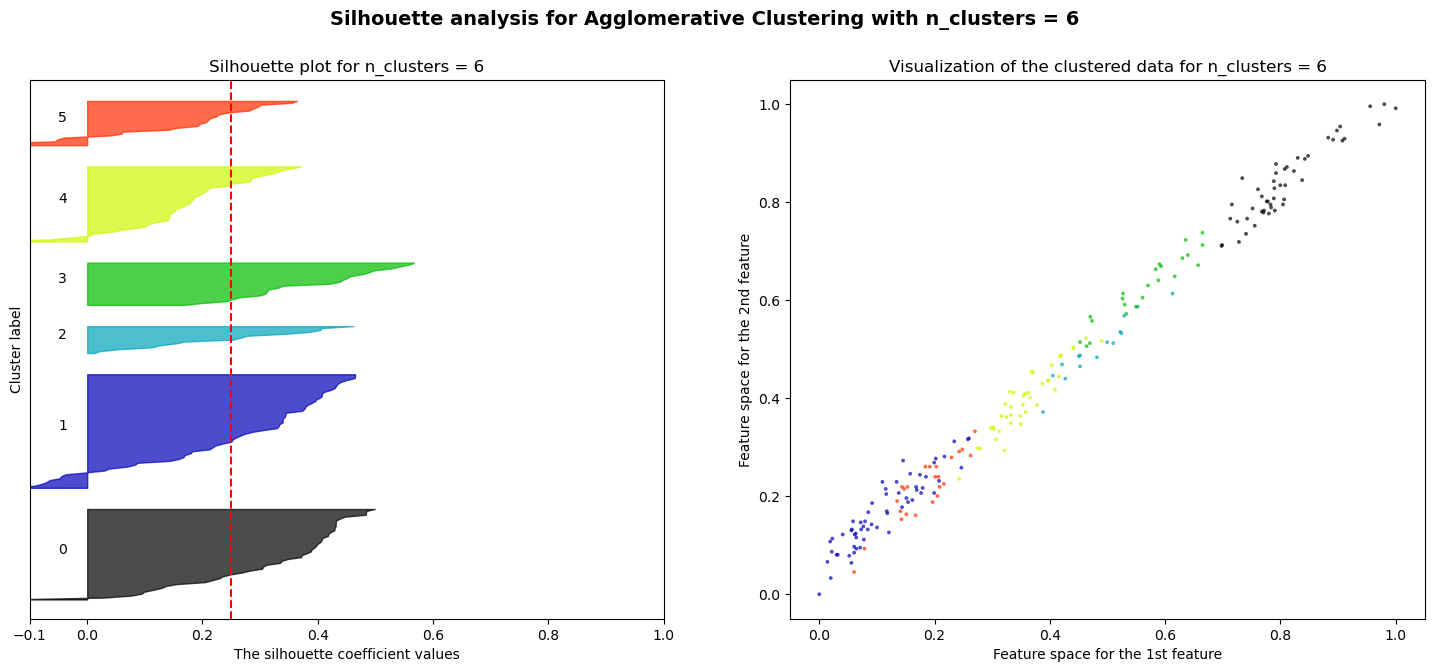

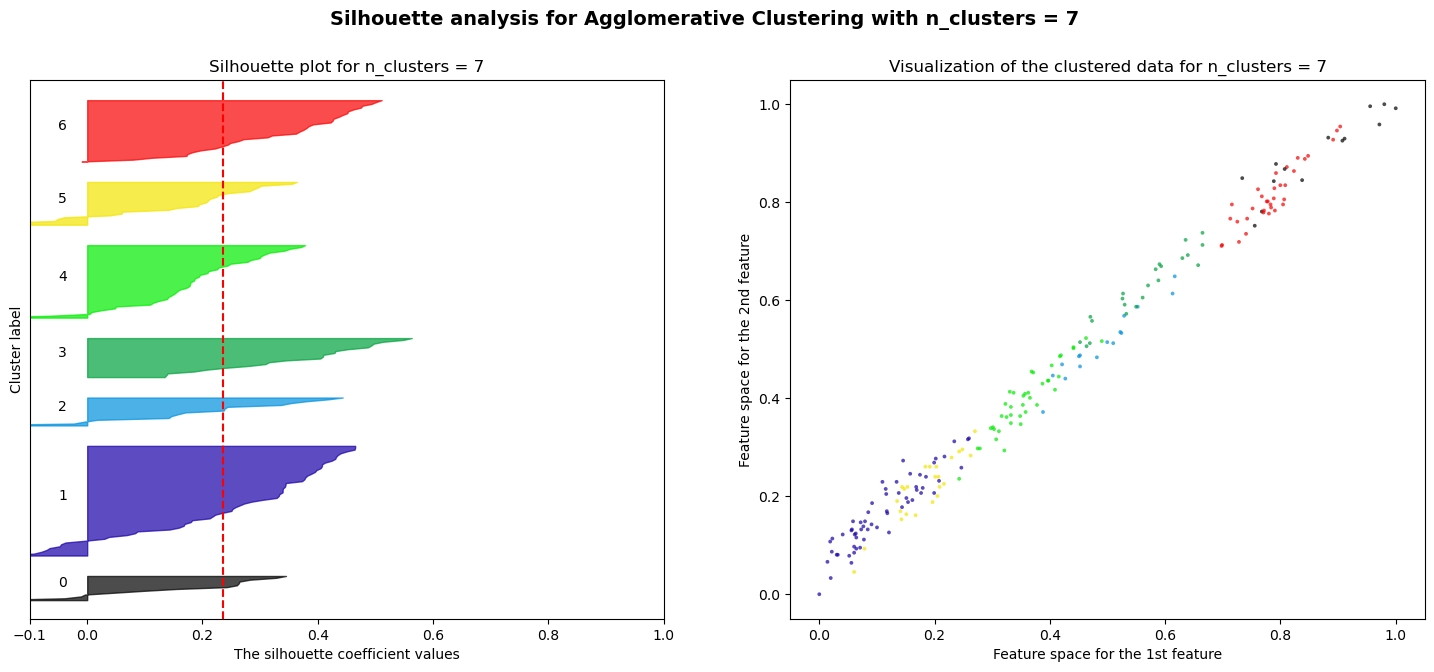

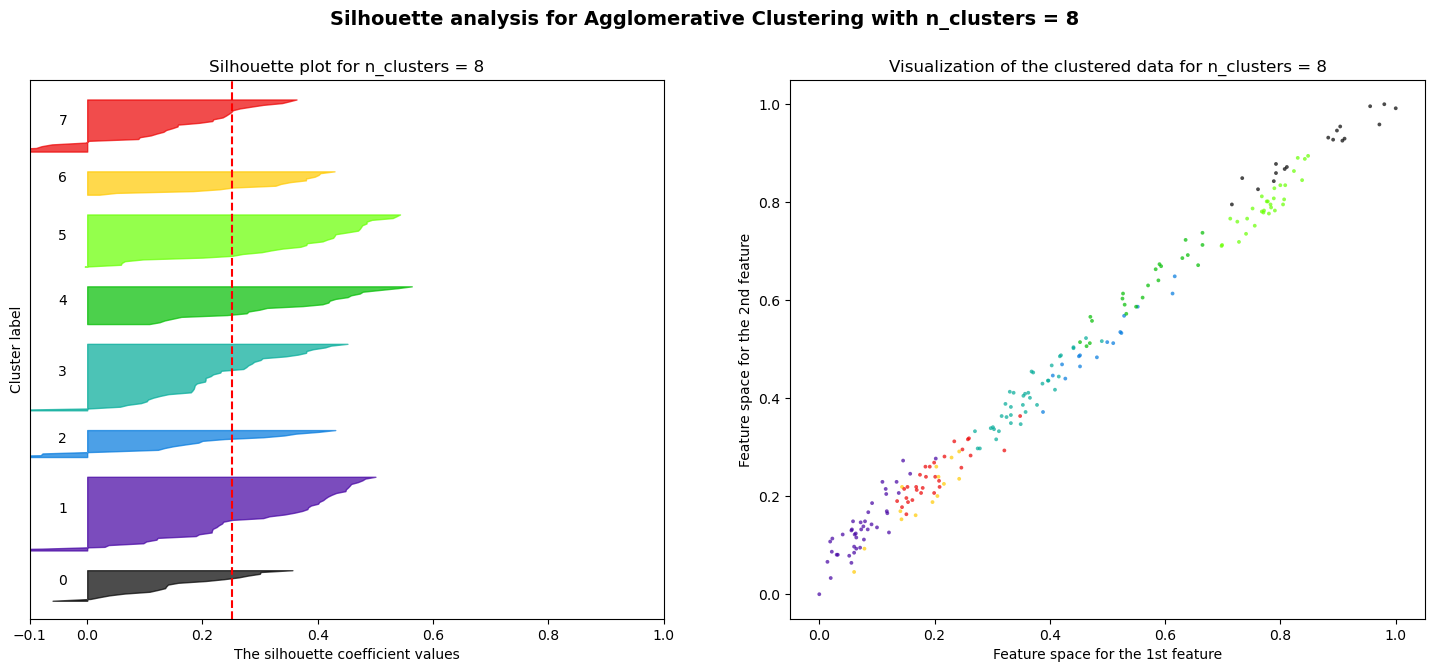

In [111]:
from sklearn.mixture import GaussianMixture

for n_clusters in range_n_clusters:
    # Создаём подграфики с 1 строкой и 2 колонками
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # Первый подграфик: график силуэтного коэффициента
    ax1.set_xlim([-0.1, 1])
    ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

    # Инициализируем Agglomerative Clustering
    clusterer = GaussianMixture(n_components=n_clusters, random_state=42)
    cluster_labels = clusterer.fit_predict(X)

    # Средний силуэтный коэффициент
    silhouette_avg = silhouette_score(X, cluster_labels)
    print(f"For n_clusters = {n_clusters}, the average silhouette_score is: {silhouette_avg:.4f}")

    # Считаем силуэтные коэффициенты для каждого образца
    sample_silhouette_values = silhouette_samples(X, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Силуэтные коэффициенты для кластера i
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Подписываем номера кластеров
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        y_lower = y_upper + 10

    ax1.set_title(f"Silhouette plot for n_clusters = {n_clusters}")
    ax1.set_xlabel("The silhouette coefficient values")
    ax1.set_ylabel("Cluster label")

    # Вертикальная линия для среднего силуэтного коэффициента
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])  # Убираем метки на оси Y
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # Второй подграфик: визуализация кластеров
    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(X[:, 0], X[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k")

    ax2.set_title(f"Visualization of the clustered data for n_clusters = {n_clusters}")
    ax2.set_xlabel("Feature space for the 1st feature")
    ax2.set_ylabel("Feature space for the 2nd feature")

    plt.suptitle(f"Silhouette analysis for Agglomerative Clustering with n_clusters = {n_clusters}", fontsize=14, fontweight="bold")

plt.show()